In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/iragena/country-schools/Country Schools.csv


In [2]:

import os

# Check the uploaded dataset files
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/datasets/iragena/country-schools/Country Schools.csv



# <span style="color:#17365D">Lab 2: Anomaly Detection and Cluster Analysis</span>

## <span style="color:#159A9C">1. Introduction</span>

In this lab, I will analyze school installation data from 47 counties in Kenya using Python in a Kaggle Notebook.

The dataset contains information about the total number of schools, installed schools, pending installations, installation percentages, and installed devices.

First, I will clean and prepare the dataset. Then, I will use anomaly detection to find counties with unusual installation patterns and cluster analysis to group counties with similar characteristics.

### <span style="color:#159A9C">1.1 Objectives</span>

The objectives of this lab are:

1. To load and understand the dataset.
2. To clean the data and handle missing values.
3. To detect unusual records using anomaly detection.
4. To group similar counties using cluster analysis.
5. To visualize and explain the results.

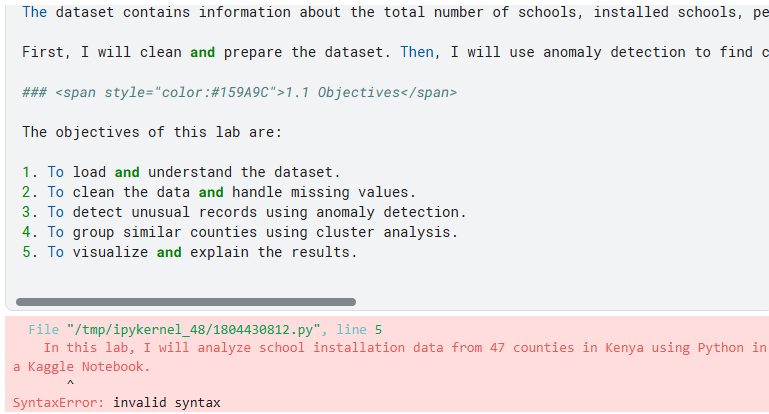


## <span style="color:#159A9C">2. Importing Python Libraries</span>

In this step, I will import the Python libraries needed to clean the dataset, analyze the data, and display the results using charts.


In [3]:

# Libraries for working with data
import pandas as pd
import numpy as np

# Libraries for creating charts
import matplotlib.pyplot as plt
import seaborn as sns

# Libraries for anomaly detection and clustering
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Set chart style
sns.set_theme(style="whitegrid")

# Make results reproducible
RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


**Interpretation:**

All the required libraries were imported successfully. I will use Pandas and NumPy to work with the dataset, Matplotlib and Seaborn to create charts, and Scikit-learn to detect unusual records and group similar counties.


## <span style="color:#159A9C">3. Loading the Dataset</span>

In this step, I will load the Country Schools dataset into the notebook so that I can work with it using Python.


In [4]:

# Find the uploaded dataset
from pathlib import Path

file_path = list(
    Path('/kaggle/input').rglob('Country Schools.csv')
)[0]

# Load the dataset
df = pd.read_csv(file_path)

# Check if the dataset loaded correctly
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five rows
print("\nFirst Five Rows:")
display(df.head())

# Display the last five rows
print("\nLast Five Rows:")
display(df.tail())


Dataset loaded successfully!
Dataset shape: (50, 8)

First Five Rows:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358.0,37.0,321.0,10.34%,3744.0,74.0,1
1,HOMA BAY,875.0,552.0,323.0,63.09%,22982.0,1104.0,2
2,WEST POKOT,498.0,242.0,256.0,48.59%,15114.0,484.0,3
3,KITUI,1238.0,1200.0,38.0,96.93%,42162.0,2400.0,4
4,TANA RIVER,159.0,143.0,16.0,89.94%,7415.0,286.0,5



Last Five Rows:


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
45,EMBU,381.0,248.0,133.0,65.09%,8438.0,496.0,46
46,SAMBURU,146.0,49.0,97.0,33.56%,2891.0,98.0,47
47,TOTAL,21729.0,14629.0,7100.0,67.32%,723618.0,29258.0,48
48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49
49,NaN,NaN,NaN,NaN,NaN,NaN,NaN,50



**Interpretation:**

The dataset was loaded successfully and contains 50 rows and 8 columns. The first five rows show school installation details for different counties in Kenya, including the total number of schools, installed schools, and pending installations.

The last five rows reveal a TOTAL row that summarizes the data and two incomplete rows with missing values.

These records need to be handled during data cleaning so that the analysis focuses on the 47 counties of Kenya.


## <span style="color:#159A9C">4. Checking the Dataset</span>

### <span style="color:#159A9C">4.1 Checking Data Types</span>

I will check the data type of each column to see if any values need to be converted.

In [5]:

# Check the data type of each column
print("Data Types:")
print(df.dtypes)


Data Types:
SNO                       object
TOTALSCHOOLS             float64
TotalSchoolsInstalled    float64
SchoolsPending           float64
PercentageInstalled       object
InstalledLDDs            float64
InstalledTDDs            float64
FID                        int64
dtype: object


### <span style="color:#159A9C">4.2 Checking Missing Values</span>

I will check whether any columns contain missing values.

In [6]:

# Check for missing values
print("Missing Values:")
print(df.isnull().sum())


Missing Values:
SNO                      2
TOTALSCHOOLS             2
TotalSchoolsInstalled    2
SchoolsPending           2
PercentageInstalled      2
InstalledLDDs            2
InstalledTDDs            2
FID                      0
dtype: int64


### <span style="color:#159A9C">4.3 Checking Duplicate Records</span>

I will check if any records are repeated in the dataset.

In [7]:
# Check duplicate rows
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


**Interpretation:**

The dataset has no duplicate records. This means there are no repeated rows that need to be removed.


## <span style="color:#159A9C">5. Data Cleaning and Preprocessing</span>

In this step, I will remove unnecessary rows, correct the data types, and prepare the dataset for analysis.



### <span style="color:#159A9C">5.1 Removing Unnecessary Rows</span>

I will remove the empty rows and the TOTAL row so that the dataset only contains information about individual counties.


In [8]:

# Make a copy of the original dataset
df_clean = df.copy()

# Remove rows without county names
df_clean = df_clean.dropna(subset=['SNO'])

# Remove extra spaces from county names
df_clean['SNO'] = df_clean['SNO'].str.strip()

# Remove the TOTAL summary row
df_clean = df_clean[df_clean['SNO'] != 'TOTAL'].copy()

# Reset row numbers
df_clean = df_clean.reset_index(drop=True)

# Check the number of remaining records
print("Cleaned dataset shape:", df_clean.shape)


Cleaned dataset shape: (47, 8)



**Interpretation:**

I removed the two empty rows and the TOTAL row because they do not represent individual counties. The dataset now contains 47 rows and 8 columns, representing the 47 counties of Kenya.



### <span style="color:#159A9C">5.2 Correcting Data Types</span>

I will change the percentage values into numbers and make sure the school and device counts have the correct data types.


In [9]:

# Convert installation percentages into numbers
df_clean['PercentageInstalled'] = pd.to_numeric(
    df_clean['PercentageInstalled'].str.replace('%', '', regex=False),
    errors='coerce'
)

# Columns containing school and device counts
count_columns = [
    'TOTALSCHOOLS',
    'TotalSchoolsInstalled',
    'SchoolsPending',
    'InstalledLDDs',
    'InstalledTDDs'
]

# Convert count columns into whole numbers
df_clean[count_columns] = df_clean[count_columns].astype(int)

# Display updated data types
print(df_clean.dtypes)


SNO                       object
TOTALSCHOOLS               int64
TotalSchoolsInstalled      int64
SchoolsPending             int64
PercentageInstalled      float64
InstalledLDDs              int64
InstalledTDDs              int64
FID                        int64
dtype: object



**Interpretation:**

I converted the Percentage Installed column from text into numbers by removing the percentage symbol. I also changed the school and device counts into whole numbers. This makes the data easier to use in calculations and machine learning.



### <span style="color:#159A9C">5.3 Checking the Cleaned Dataset</span>

After cleaning the data, I will check the remaining records and missing values to make sure the dataset is ready for analysis.


In [10]:

# Display the first five cleaned records
display(df_clean.head())

# Check remaining missing values
print("Remaining missing values:")
print(df_clean.isnull().sum())

# Check the final dataset size
print("\nFinal dataset shape:", df_clean.shape)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled,InstalledLDDs,InstalledTDDs,FID
0,TURKANA,358,37,321,10.34,3744,74,1
1,HOMA BAY,875,552,323,63.09,22982,1104,2
2,WEST POKOT,498,242,256,48.59,15114,484,3
3,KITUI,1238,1200,38,96.93,42162,2400,4
4,TANA RIVER,159,143,16,89.94,7415,286,5


Remaining missing values:
SNO                      0
TOTALSCHOOLS             0
TotalSchoolsInstalled    0
SchoolsPending           0
PercentageInstalled      0
InstalledLDDs            0
InstalledTDDs            0
FID                      0
dtype: int64

Final dataset shape: (47, 8)



**Interpretation:**

After cleaning, the dataset contains 47 records and 8 columns, with no missing values. Each record represents one county in Kenya. The data is now ready for further preparation and analysis.



## <span style="color:#159A9C">6. Preparing Data for Machine Learning</span>

### <span style="color:#159A9C">6.1 Checking Data Accuracy</span>

Before starting machine learning, I will check if the school totals and installation percentages are correct.


In [11]:

# Check if installed and pending schools equal total schools
school_check = (
    df_clean['TotalSchoolsInstalled'] +
    df_clean['SchoolsPending']
    == df_clean['TOTALSCHOOLS']
)

print("School totals are correct:", school_check.all())

# Check the installation percentages
calculated_percentage = (
    df_clean['TotalSchoolsInstalled'] /
    df_clean['TOTALSCHOOLS'] * 100
)

difference = (
    calculated_percentage - df_clean['PercentageInstalled']
).abs()

print("Largest percentage difference:", round(difference.max(), 3))

# Check duplicate county names
print("Duplicate counties:", df_clean['SNO'].duplicated().sum())

# Calculate total schools
print("Total schools:", df_clean['TOTALSCHOOLS'].sum())
print("Installed schools:", df_clean['TotalSchoolsInstalled'].sum())
print("Pending schools:", df_clean['SchoolsPending'].sum())

# Calculate overall installation rate
overall_rate = (
    df_clean['TotalSchoolsInstalled'].sum() /
    df_clean['TOTALSCHOOLS'].sum() * 100
)

print("Overall installation rate:", round(overall_rate, 2), "%")


School totals are correct: True
Largest percentage difference: 0.005
Duplicate counties: 0
Total schools: 21729
Installed schools: 14629
Pending schools: 7100
Overall installation rate: 67.32 %



**Interpretation:**

The results show that the school totals are correct and there are no duplicate counties. The small difference in installation percentages is due to rounding.

Out of 21,729 schools, 14,629 have completed installations, while 7,100 are still pending. This gives an overall installation rate of 67.32%.



### <span style="color:#159A9C">6.2 Descriptive Statistics</span>

I will use descriptive statistics to understand how the number of schools and installation progress differ across counties.


In [12]:

# Select columns for statistical analysis
columns = [
    'TOTALSCHOOLS',
    'TotalSchoolsInstalled',
    'SchoolsPending',
    'PercentageInstalled'
]

# Display summary statistics
display(df_clean[columns].describe().round(2))


,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled
count,47.00,47.00,47.00,47.00
mean,462.32,311.26,151.06,63.92
std,254.20,229.00,113.80,25.85
min,93.00,8.00,4.00,4.55
25%,251.50,156.50,52.50,50.30
50%,413.00,307.00,130.00,65.00
75%,633.50,408.50,243.00,84.94
max,1238.00,1200.00,448.00,96.93



**Interpretation:**

The statistics show that the number of schools and installation progress differ across counties.

On average, each county has about 462 schools, with 311 installed and 151 still pending.

The installation percentages range from 4.55% to 96.93%, showing that some counties have made more progress than others.

These differences will help us understand the results of anomaly detection and clustering.



### <span style="color:#159A9C">6.3 Selecting Features</span>

I will select three features for machine learning: total schools, installation percentage, and average LDDs per installed school.

These features will help me compare the counties using their school numbers, installation progress, and installed devices.


In [13]:

# Create a copy for machine learning
df_model = df_clean.copy()

# Calculate LDDs per installed school
df_model['LDDsPerInstalledSchool'] = (
    df_model['InstalledLDDs'] /
    df_model['TotalSchoolsInstalled'].replace(0, np.nan)
)

# Select features
features = [
    'TOTALSCHOOLS',
    'PercentageInstalled',
    'LDDsPerInstalledSchool'
]

X = df_model[features].copy()

# Check the selected data
print("Selected data shape:", X.shape)
print("Missing values:", X.isnull().sum().sum())

display(X.head().round(2))


Selected data shape: (47, 3)
Missing values: 0


,TOTALSCHOOLS,PercentageInstalled,LDDsPerInstalledSchool
0,358,10.34,101.19
1,875,63.09,41.63
2,498,48.59,62.45
3,1238,96.93,35.14
4,159,89.94,51.85



**Interpretation:**

I selected three features to compare the counties based on their school numbers, installation progress, and average number of LDDs per installed school.

The selected data contains 47 records and 3 features, with no missing values. These features will be used for anomaly detection and clustering.



### <span style="color:#159A9C">6.4 Standardizing the Features</span>

The selected features have different numerical ranges. I will standardize them so that features with larger values do not have too much influence on the machine learning results.


In [14]:

# Standardize the selected features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Display the standardized data
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

print("Standardized data shape:", X_scaled_df.shape)

display(X_scaled_df.head().round(2))


Standardized data shape: (47, 3)


,TOTALSCHOOLS,PercentageInstalled,LDDsPerInstalledSchool
0,-0.41,-2.10,2.49
1,1.64,-0.03,-0.59
2,0.14,-0.60,0.49
3,3.08,1.29,-0.92
4,-1.21,1.02,-0.06



**Interpretation:**

I standardized the selected features so that they are measured on a similar scale. This helps prevent features with larger numbers from having too much influence on the results.

The data is now prepared for anomaly detection and cluster analysis.



## <span style="color:#17365D">7. Experiment 1: Anomaly Detection</span>

### <span style="color:#159A9C">7.1 Applying Isolation Forest</span>

In this experiment, I will use the Isolation Forest algorithm to identify counties with unusual school installation patterns.

The model will use the three features selected earlier. I will set the expected proportion of anomalies to 10%.


In [15]:

# Create the Isolation Forest model
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.10,
    random_state=42
)

# Train the model and detect anomalies
predictions = iso_forest.fit_predict(X_scaled)

# Store the results
df_anomaly = df_model.copy()
df_anomaly['Anomaly'] = predictions

# Label normal and unusual counties
df_anomaly['Status'] = df_anomaly['Anomaly'].map({
    1: 'Normal',
    -1: 'Anomaly'
})

# Display results
print("Anomaly Detection Results:")
print(df_anomaly['Status'].value_counts())


Anomaly Detection Results:
Status
Normal     42
Anomaly     5
Name: count, dtype: int64


**Interpretation:**

The Isolation Forest model identified 5 counties with unusual
installation patterns, while the remaining 42 counties were
classified as normal.

This shows that most counties have similar patterns, while a
small number have results that are different from the others.


### <span style="color:#159A9C">7.2 Identifying Anomalous Counties</span>

I will display the counties identified as anomalies and check their installation information to understand why they stand out.


In [16]:

# Select counties identified as anomalies
anomalies = df_anomaly[
    df_anomaly['Anomaly'] == -1
]

# Display the counties and their installation information
display(
    anomalies[
        ['SNO', 'TOTALSCHOOLS',
         'PercentageInstalled',
         'LDDsPerInstalledSchool', 'Status']
    ].round(2)
)


,SNO,TOTALSCHOOLS,PercentageInstalled,LDDsPerInstalledSchool,Status
0,TURKANA,358,10.34,101.19,Anomaly
3,KITUI,1238,96.93,35.14,Anomaly
30,MANDERA,198,4.55,116.22,Anomaly
36,WAJIR,211,5.21,77.73,Anomaly
38,MARSABIT,138,5.80,75.75,Anomaly


**Interpretation:**

The model identified Turkana, Kitui, Mandera, Marsabit,
and Wajir as counties with unusual installation patterns.

Mandera, Marsabit, Wajir, and Turkana have very low
installation percentages. Kitui is different because it
has a high number of schools and a high installation rate.

These counties were identified because their combined
features are different from most other counties. Being
an anomaly does not necessarily mean that the data is wrong.


### <span style="color:#159A9C">7.3 Visualizing Anomaly Detection Results</span>

I will use a scatter plot to show the normal and unusual counties based on their total number of schools and installation percentages.


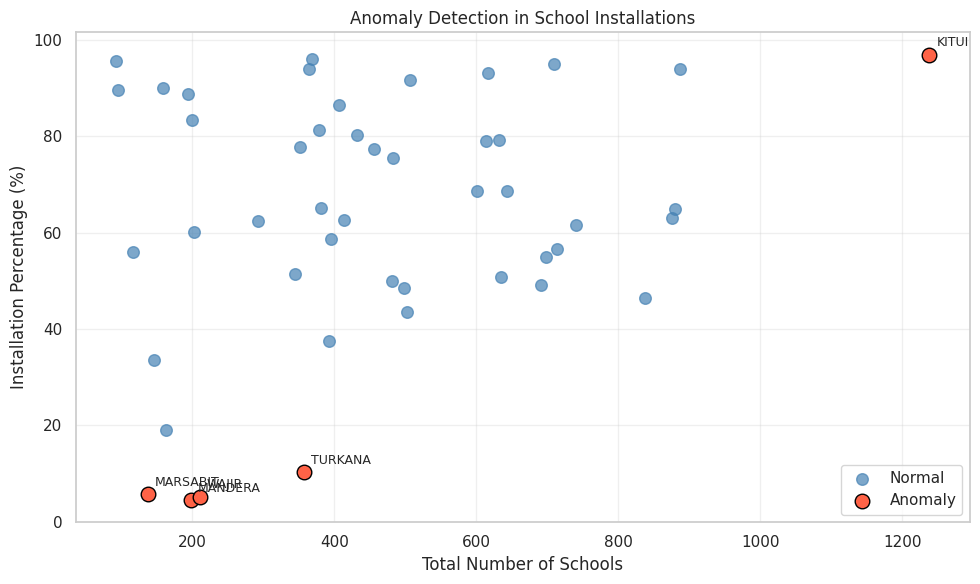

In [17]:

# Separate normal and anomalous counties
normal = df_anomaly[df_anomaly['Anomaly'] == 1]
anomaly = df_anomaly[df_anomaly['Anomaly'] == -1]

plt.figure(figsize=(10, 6))

# Plot normal counties
plt.scatter(
    normal['TOTALSCHOOLS'],
    normal['PercentageInstalled'],
    color='steelblue',
    label='Normal',
    s=70,
    alpha=0.7
)

# Plot anomalous counties
plt.scatter(
    anomaly['TOTALSCHOOLS'],
    anomaly['PercentageInstalled'],
    color='tomato',
    label='Anomaly',
    s=110,
    edgecolor='black'
)

# Label anomalous counties
for _, row in anomaly.iterrows():
    plt.annotate(
        row['SNO'],
        (row['TOTALSCHOOLS'], row['PercentageInstalled']),
        xytext=(5, 6),
        textcoords='offset points',
        fontsize=9
    )

plt.title('Anomaly Detection in School Installations')
plt.xlabel('Total Number of Schools')
plt.ylabel('Installation Percentage (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Interpretation:**

The scatter plot shows normal counties in blue and anomalous counties in red.

The five unusual counties are highlighted to make them easier to identify. Most of these counties have low installation percentages, while Kitui has a very high installation rate.

The chart helps us see how these counties differ from the others. The model used all three selected features, although the chart displays only two.



## <span style="color:#17365D">8. Experiment 2: Cluster Analysis</span>

### <span style="color:#159A9C">8.1 Finding the Best Number of Clusters</span>

I will use K-Means and the Silhouette Score to find a suitable number of clusters. I will test values of K from 2 to 8 and choose the one with the highest score.


In [18]:

# Test different numbers of clusters
k_values = range(2, 9)
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

# Display the results
for k, score in zip(k_values, silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

# Select the best number of clusters
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("\nBest number of clusters:", best_k)


K = 2: Silhouette Score = 0.4442
K = 3: Silhouette Score = 0.2797
K = 4: Silhouette Score = 0.2978
K = 5: Silhouette Score = 0.2914
K = 6: Silhouette Score = 0.3001
K = 7: Silhouette Score = 0.3064
K = 8: Silhouette Score = 0.2989

Best number of clusters: 2


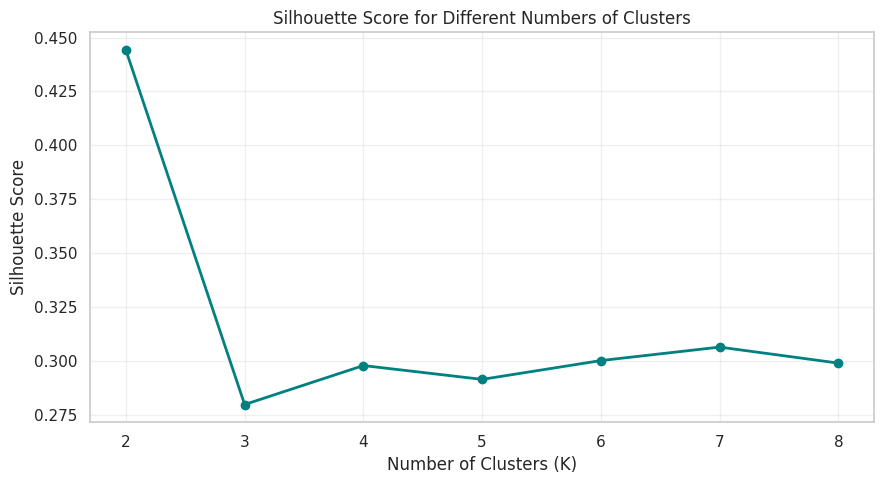

In [19]:

# Plot silhouette scores
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker='o',
    color='teal',
    linewidth=2
)

plt.title('Silhouette Score for Different Numbers of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Interpretation:**

I tested different numbers of clusters from 2 to 8. The highest Silhouette Score was 0.4442 when K = 2.

This means that two clusters give the clearest grouping among the values tested. Therefore, I will use two clusters for the analysis.



### <span style="color:#159A9C">8.2 Applying K-Means Clustering</span>

I will use K-Means to divide the 47 counties into groups based on their school numbers, installation percentages, and average LDDs per installed school.


In [20]:

# Create the K-Means model
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

# Group the counties
cluster_labels = kmeans.fit_predict(X_scaled)

# Store cluster results
df_cluster = df_model.copy()
df_cluster['Cluster'] = cluster_labels + 1

# Display the number of counties in each cluster
print("Counties in each cluster:")
print(df_cluster['Cluster'].value_counts().sort_index())

# Display sample records
display(
    df_cluster[
        ['SNO', 'TOTALSCHOOLS',
         'PercentageInstalled', 'Cluster']
    ].head()
)


Counties in each cluster:
Cluster
1    41
2     6
Name: count, dtype: int64


,SNO,TOTALSCHOOLS,PercentageInstalled,Cluster
0,TURKANA,358,10.34,2
1,HOMA BAY,875,63.09,1
2,WEST POKOT,498,48.59,1
3,KITUI,1238,96.93,1
4,TANA RIVER,159,89.94,1



**Interpretation:**

K-Means divided the 47 counties into two clusters. Cluster 1 contains 41 counties, while Cluster 2 contains 6 counties.

This shows that most counties share similar installation patterns, while a smaller group has different characteristics.



### <span style="color:#159A9C">8.3 Comparing the Clusters</span>

I will compare the average number of schools, installation percentages, and LDDs per installed school in each cluster.


In [21]:

# Calculate average values for each cluster
cluster_summary = df_cluster.groupby('Cluster').agg(
    Counties=('SNO', 'count'),
    AverageSchools=('TOTALSCHOOLS', 'mean'),
    AverageInstallation=('PercentageInstalled', 'mean'),
    AverageLDDs=('LDDsPerInstalledSchool', 'mean')
).round(2)

display(cluster_summary)


,Counties,AverageSchools,AverageInstallation,AverageLDDs
Cluster,,,,
1,41,500.37,71.36,49.04
2,6,202.33,13.08,80.08



**Interpretation:**

Cluster 1 contains 41 counties with an average installation percentage of 71.36%. These counties generally have more schools and higher installation progress.

Cluster 2 contains 6 counties with an average installation percentage of 13.08%. These counties have fewer schools on average and more LDDs per installed school.

The results show a clear difference in installation progress between the two groups.



### <span style="color:#159A9C">8.4 Visualizing the Clusters</span>

I will create a scatter plot to show how the counties are grouped according to their total number of schools and installation percentages.


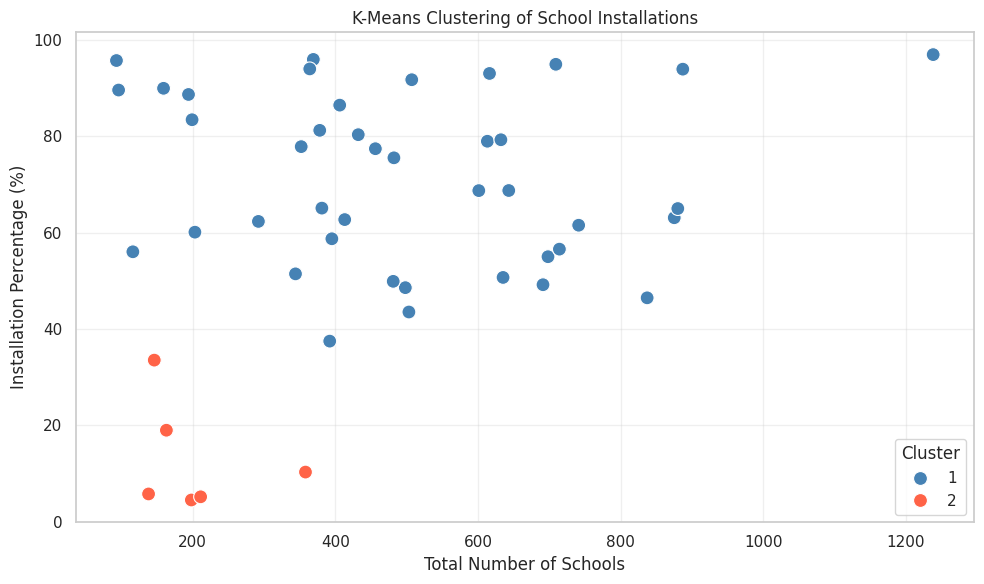

In [22]:

# Create a scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cluster,
    x='TOTALSCHOOLS',
    y='PercentageInstalled',
    hue='Cluster',
    palette=['steelblue', 'tomato'],
    s=100
)

plt.title('K-Means Clustering of School Installations')
plt.xlabel('Total Number of Schools')
plt.ylabel('Installation Percentage (%)')
plt.legend(title='Cluster')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



**Interpretation:**

The scatter plot shows how the counties are divided into two clusters based on their school installation patterns.

Most counties belong to Cluster 1, which generally has higher installation percentages. Cluster 2 contains counties with lower installation percentages.

The chart helps show the difference between the two groups. The clustering itself was based on all three selected features.



### <span style="color:#159A9C">8.5 Counties with Lower Installation Progress</span>

I will display the counties in Cluster 2 to see which areas have lower installation progress.


In [23]:

# Select counties in Cluster 2
cluster_2 = df_cluster[
    df_cluster['Cluster'] == 2
]

# Display counties in order of installation percentage
display(
    cluster_2[
        ['SNO', 'TOTALSCHOOLS',
         'TotalSchoolsInstalled',
         'SchoolsPending',
         'PercentageInstalled']
    ].sort_values('PercentageInstalled').reset_index(drop=True)
)


,SNO,TOTALSCHOOLS,TotalSchoolsInstalled,SchoolsPending,PercentageInstalled
0,MANDERA,198,9,189,4.55
1,WAJIR,211,11,200,5.21
2,MARSABIT,138,8,130,5.80
3,TURKANA,358,37,321,10.34
4,GARISSA,163,31,132,19.02
5,SAMBURU,146,49,97,33.56



**Interpretation:**

Cluster 2 contains Mandera, Wajir, Marsabit, Turkana, Garissa, and Samburu.

These counties have relatively low school installation percentages compared to most other counties.

The results suggest that these counties could be given more attention when planning future school installations. However, further investigation would be needed to understand why their installation progress is lower.



## <span style="color:#17365D">9. Comparison of Anomaly Detection and Clustering</span>

### <span style="color:#159A9C">9.1 Comparing the Results</span>

I will compare the results from Isolation Forest and K-Means to see which clusters contain the unusual counties.


In [24]:

# Combine anomaly detection and clustering results
comparison = df_cluster[
    ['SNO', 'Cluster', 'PercentageInstalled']
].merge(
    df_anomaly[['SNO', 'Status']],
    on='SNO',
    validate='one_to_one'
)

# Compare normal and unusual counties in each cluster
comparison_table = pd.crosstab(
    comparison['Cluster'],
    comparison['Status']
)

display(comparison_table)


Status,Anomaly,Normal
Cluster,,
1,1,40
2,4,2


**Interpretation:**

The results show that Cluster 1 contains 40 normal counties and only 1 anomaly.

Cluster 2 contains 4 anomalies and 2 normal counties.

This shows that most unusual counties belong to Cluster 2, which has a lower average installation rate. However, not every county in this cluster is an anomaly.


### <span style="color:#159A9C">9.2 Visualizing the Comparison</span>

I will use a bar chart to compare the number of normal and unusual counties in each cluster.


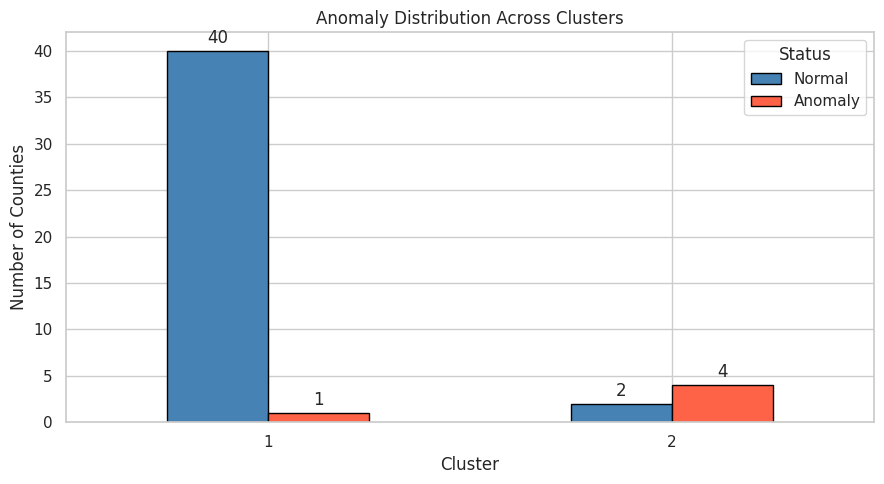

In [25]:

# Arrange columns for the chart
plot_data = comparison_table.reindex(
    columns=['Normal', 'Anomaly'],
    fill_value=0
)

# Create a bar chart
ax = plot_data.plot(
    kind='bar',
    figsize=(9, 5),
    color=['steelblue', 'tomato'],
    edgecolor='black'
)

plt.title('Anomaly Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Counties')
plt.xticks(rotation=0)
plt.legend(title='Status')

# Add values above the bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()


**Interpretation:**

The chart shows that Cluster 1 contains mostly normal counties, while Cluster 2 has more anomalies than normal counties.

This means that the counties with unusual installation patterns are mainly found in the group with lower installation progress.

The two algorithms help us understand the data in different ways. Isolation Forest identifies unusual counties, while K-Means groups counties with similar characteristics.


### <span style="color:#159A9C">9.3 Identifying Anomalies in Each Cluster</span>

I will display the unusual counties and their clusters to understand how the results from both algorithms are related.


In [26]:

# Display anomalous counties with their clusters
unusual_counties = comparison[
    comparison['Status'] == 'Anomaly'
]

display(
    unusual_counties[
        ['SNO', 'Cluster', 'PercentageInstalled', 'Status']
    ].sort_values('Cluster')
    .reset_index(drop=True)
)


,SNO,Cluster,PercentageInstalled,Status
0,KITUI,1,96.93,Anomaly
1,TURKANA,2,10.34,Anomaly
2,MANDERA,2,4.55,Anomaly
3,WAJIR,2,5.21,Anomaly
4,MARSABIT,2,5.80,Anomaly


**Interpretation:**

The results show that four of the five unusual counties belong to Cluster 2. These counties have very low installation percentages.

Kitui is the only anomaly in Cluster 1. Unlike the other unusual counties, Kitui has a high installation rate of 96.93%.

This shows that anomaly detection does not only identify counties with poor installation progress. It can also identify counties with unusually high results or other different characteristics.


## <span style="color:#17365D">10. Conclusion</span>

In this lab, I analyzed school installation data from 47 counties in Kenya. I cleaned the dataset and used Isolation Forest to identify 5 counties with unusual installation patterns.

I also used K-Means to group the counties into 2 clusters based on their similarities. The results showed that some counties have much lower installation progress than others.

Overall, this lab helped me understand how anomaly detection and clustering can be used to find unusual patterns, compare counties, and identify areas that may need more attention.
